# Consolidation: combining the photo model and the attribute models (RQ3)

The two pipelines look at different evidence for the same photo: the neural network sees the **pixels**, the classical models see the **312 attributes** a person ticked. This notebook asks whether a prediction that uses both is better than either alone, and how often the two agree (research question 3).

### The rule we agreed on
1. The **image model** (ViT-B/16, 224 px) proposes its **top 5** species for a photo. It has the right species in its top 5 about 96% of the time on the test photos, but ranks it first only about 82% of the time.
2. Each of the 5 candidates gets a combined score: `w × image probability + (1 − w) × attribute probability`.
3. The candidate with the highest score is the consolidated prediction.

Taking the candidates from the image model, and not only the species both models have in their top 5, means the attribute model can help choose but can never remove the right answer. With `w = 1` the rule is just the image model; with `w = 0.5` both models count equally.

### Which attribute models
Every classical model the team trained, each with the settings its own notebook chose:

| Attribute model | Settings | From |
|---|---|---|
| Logistic regression | default (L2), `tol=1e-08`, `max_iter=1000`, encoding A | `logistic_regression.ipynb` |
| Random forest | 750 trees, gini, `max_depth=30`, `max_features='sqrt'`, `min_samples_leaf=2`, encoding C | `randomForest.ipynb` |
| k-NN | the settings chosen by macro-F1 in `knn.ipynb`, read from `results/knn_best_params.json`, encoding A | `knn.ipynb` |
| k-NN + LDA | certainty-weighted attributes, LDA, then k-NN, with the settings chosen by macro-F1 in `knn_improvements.ipynb`, read from `results/knn_improvements.csv` | `knn_improvements.ipynb` |
| Decision tree | default settings, encoding A | `decisionTree.ipynb` |

### Protocol (no test leakage)
- For **every attribute model and every weight**, the score is measured on the **1,199 validation photos**, using an image model and attribute models trained on the other 4,795 training photos only.
- The **pair and weight with the best validation macro-F1** become the consolidated model.
- Only then are the final models (trained on all 5,994 training photos) scored on the 5,794 test photos. All pairs are reported on the test set for transparency, but the choice was made on validation.

### Inputs
- `results/vit/vit_b16_224px_val_probs.npz` and `results/vit/vit_b16_224px_final_test_probs.npz`: the ViT's species probabilities for every validation and test photo (section 13 of `vit.ipynb`).
- `results/vit/vit_b16_448px_final_test_probs.npz` (optional): the 448 px ViT's test probabilities, used in section 8.
- `data/cub_features_A.csv` and `data/cub_features_C.csv` from `dataPrep.ipynb`.
- The raw certainty labels (`CUB_200_2011/attributes/image_attribute_labels_clean.txt` under `data/raw/`), for the k-NN + LDA model only. If they are missing, that model is skipped.

Runs on a laptop CPU in about 5 to 10 minutes (the random forest takes most of it).

*Code written with help from Claude (Anthropic).*

## 1. Setup

In [ ]:
# --- GenAI disclosure (F20DL coursework spec, Section 8) ---
# Before this notebook I studied Ensemble Methods, Model Testing, Model Evaluation, k-NN & Data Preparation, Dimensionality Reduction, Linear Models and Decision Trees (Lecture 8, 6, 7, 3, 17, 10 and 5).
# I then used Claude (Anthropic) to explore how to combine the ViT's and attribute models' probabilities (top-5 candidates, weighted score) and choose the partner and weight on validation without test leakage.
# Based on that, and with my own views and decisions, the code and the explanatory markdown in this notebook were generated with Claude.
# I ran every cell, checked the outputs against the data, and edited the code where needed (Tengku).
# Prompt used: "from the ViT and knn notebooks, write a notebook that combines the ViT's and attribute models' probabilities (top-5 candidates, weighted score) and chooses the partner and weight on validation without test leakage. Use sklearn's KNeighborsClassifier, DecisionTreeClassifier, RandomForestClassifier, LogisticRegression, LDA and cross_validate."

import ast
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
ROOT = Path.cwd() if (Path.cwd() / "notebooks").exists() else Path.cwd().parent
DATA = ROOT / "data"
CUB = next((p.parent for p in (DATA / "raw").rglob("image_class_labels.txt")), ROOT / "CUB_200_2011")
IMAGE_RUN = ROOT / "results" / "vit"
VAL_FILE = IMAGE_RUN / "vit_b16_224px_val_probs.npz"
TEST_FILE = IMAGE_RUN / "vit_b16_224px_final_test_probs.npz"
IMAGE_NAME = "ViT-B/16 (224 px)"
OUT = ROOT / "results" / "consolidation"
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

K = 5                                            # candidates proposed by the image model
WEIGHTS = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]         # w = weight of the image model (1.0 = image model alone)
CLASSES = np.arange(1, 201)

## 2. Load both sides

The image probabilities come with the photo ids and true species, so the attribute rows are matched to exactly the same photos, in the same order. The checks stop the notebook if anything does not line up.

In [2]:
for f in (VAL_FILE, TEST_FILE):
    assert f.exists(), f"{f.relative_to(ROOT)} not found: run section 13 of vit.ipynb and copy the .npz files into results/vit/"
img_val, img_test = np.load(VAL_FILE), np.load(TEST_FILE)

feat_A = pd.read_csv(DATA / "cub_features_A.csv", index_col="image_id")
feat_C = pd.read_csv(DATA / "cub_features_C.csv", index_col="image_id")
ATTR = [c for c in feat_A.columns if "::" in c]        # attribute columns are named "body_part::value"
ATTR_C = [c for c in feat_C.columns if "::" in c]      # (C adds the "notvis::..." flags); split/label columns are left out
assert len(ATTR) == 312 and len(ATTR_C) == 340, (len(ATTR), len(ATTR_C))
y_all = feat_A["class_id"]

val_ids, test_ids = img_val["image_id"], img_test["image_id"]
assert set(val_ids) <= set(feat_A.index[feat_A.is_train == 1]), "validation photos must come from the official training split"
assert set(test_ids) == set(feat_A.index[feat_A.is_train == 0]), "test photos must be the official test split"
assert (y_all.loc[val_ids].values == img_val["class_id"]).all()
assert (y_all.loc[test_ids].values == img_test["class_id"]).all()

train_part_ids = feat_A.index[(feat_A.is_train == 1) & ~feat_A.index.isin(val_ids)]   # the 80% the selection run trained on
all_train_ids = feat_A.index[feat_A.is_train == 1]
y_val, y_test = img_val["class_id"], img_test["class_id"]
p_img_val, p_img_test = img_val["probs"], img_test["probs"]

# Certainty-weighted attributes for k-NN + LDA (as in knn_improvements.ipynb)
labels_file = CUB / "attributes" / "image_attribute_labels_clean.txt"
X_cw = None
if labels_file.exists():
    labels = pd.read_csv(labels_file, sep=r"\s+", header=None, usecols=[0, 1, 3], names=["image_id", "attr_id", "certainty"])
    names = pd.read_csv(CUB / "attributes" / "attributes.txt", sep=" ", header=None,
                        names=["attr_id", "attr_name"]).set_index("attr_id").attr_name
    certainty = labels.pivot(index="image_id", columns="attr_id", values="certainty").rename(columns=names)
    confidence = certainty.loc[feat_A.index, ATTR].replace({1: 0.0, 2: 0.5, 3: 0.75, 4: 1.0})
    X_cw = (2 * feat_A[ATTR] - 1) * confidence      # present -> +confidence, absent -> -confidence, not visible -> 0
else:
    print(f"{labels_file} not found: k-NN + LDA will be skipped")

print(f"image model: {img_val['model']} (validation), {img_test['model']} (test)")
print(f"photos: train part {len(train_part_ids):,} | validation {len(val_ids):,} | all training {len(all_train_ids):,} | "
      f"test {len(test_ids):,}")

image model: vit_b16_224px_lr0.003 (validation), vit_b16_224px_final (test)
photos: train part 4,795 | validation 1,199 | all training 5,994 | test 5,794


## 3. Attribute models

Each model is trained twice, mirroring the image model: once on the 4,795-photo training part (to predict the validation photos) and once on all 5,994 training photos (to predict the test photos). Their test scores should match the team's notebooks (the random forest and decision tree can differ slightly because of randomness). The two k-NN models read their settings from the result files of `knn.ipynb` and `knn_improvements.ipynb`, so they always match whatever those notebooks chose.

The random forest is built in batches of 50 trees whose probabilities are averaged. That gives the same 750-tree forest without holding all 750 trees in memory at once.

In [3]:
def forest_proba(X, fit_ids, pred_ids, n_trees=750, batch=50):
    total = np.zeros((len(pred_ids), len(CLASSES)))
    for i in range(n_trees // batch):
        rf = RandomForestClassifier(n_estimators=batch, criterion="gini", max_depth=30, max_features="sqrt",
                                    min_samples_leaf=2, random_state=RANDOM_STATE + i, n_jobs=-1)
        rf.fit(X.loc[fit_ids], y_all.loc[fit_ids])
        assert (rf.classes_ == CLASSES).all()
        total += rf.predict_proba(X.loc[pred_ids]) * batch
    return total / n_trees


def sk_proba(make, X, fit_ids, pred_ids):
    model = make().fit(X.loc[fit_ids], y_all.loc[fit_ids])
    assert (model.classes_ == CLASSES).all()            # column j = species j + 1, as in the image probabilities
    return model.predict_proba(X.loc[pred_ids])


# k-NN settings as chosen (by macro-F1) in knn.ipynb and knn_improvements.ipynb
KNN_PARAMS = json.loads((ROOT / "results" / "knn_best_params.json").read_text())["params"]
improvements = pd.read_csv(ROOT / "results" / "knn_improvements.csv", index_col=0)
LDA_PARAMS = ast.literal_eval(improvements.loc["Extraction: LDA on certainty-weighted", "settings"])
print("k-NN:", KNN_PARAMS)
print("k-NN + LDA:", LDA_PARAMS)

ATTR_MODELS = {
    "Logistic regression": lambda f, p: sk_proba(lambda: LogisticRegression(tol=1e-08, max_iter=1000), feat_A[ATTR], f, p),
    "Random forest": lambda f, p: forest_proba(feat_C[ATTR_C], f, p),
    "k-NN": lambda f, p: sk_proba(lambda: KNeighborsClassifier(**KNN_PARAMS), feat_A[ATTR], f, p),
    "k-NN + LDA (certainty-weighted)": lambda f, p: sk_proba(
        lambda: Pipeline([("lda", LDA()), ("knn", KNeighborsClassifier())]).set_params(**LDA_PARAMS), X_cw, f, p),
    "Decision tree": lambda f, p: sk_proba(lambda: DecisionTreeClassifier(random_state=RANDOM_STATE), feat_A[ATTR], f, p),
}
if X_cw is None:
    ATTR_MODELS.pop("k-NN + LDA (certainty-weighted)")

P_VAL, P_TEST = {}, {}
for name, run in ATTR_MODELS.items():
    t0 = time.time()
    P_VAL[name] = run(train_part_ids, val_ids)
    P_TEST[name] = run(all_train_ids, test_ids)
    print(f"{name}: {time.time() - t0:.0f}s")


def scores(y, pred, probs=None):
    out = {"accuracy": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro", labels=CLASSES)}
    if probs is not None:
        out["top5_accuracy"] = top_k_accuracy_score(y, probs, k=5, labels=CLASSES)
    return out


single = pd.DataFrame(
    [{"model": IMAGE_NAME, "data": "images", **{f"val {k}": v for k, v in scores(y_val, p_img_val.argmax(1) + 1).items()},
      **{f"test {k}": v for k, v in scores(y_test, p_img_test.argmax(1) + 1, p_img_test).items()}}] +
    [{"model": name, "data": "attributes",
      **{f"val {k}": v for k, v in scores(y_val, P_VAL[name].argmax(1) + 1).items()},
      **{f"test {k}": v for k, v in scores(y_test, P_TEST[name].argmax(1) + 1, P_TEST[name]).items()}}
     for name in ATTR_MODELS])
single.round(4)

k-NN: {'metric': 'cosine', 'n_neighbors': 15, 'weights': 'distance'}
k-NN + LDA: {'knn__metric': 'cosine', 'knn__n_neighbors': 11, 'knn__weights': 'distance', 'lda__n_components': 64}
Logistic regression: 23s
Random forest: 9s
k-NN: 1s
k-NN + LDA (certainty-weighted): 2s
Decision tree: 1s


,model,data,val accuracy,val macro_f1,test accuracy,test macro_f1,test top5_accuracy
0,ViT-B/16 (224 px),images,0.7907,0.7867,0.8202,0.8195,0.9624
1,Logistic regression,attributes,0.4454,0.4447,0.4743,0.4802,0.7463
2,Random forest,attributes,0.4379,0.4158,0.4560,0.4355,0.7204
3,k-NN,attributes,0.3311,0.3250,0.3519,0.3489,0.6193
4,k-NN + LDA (certainty-weighted),attributes,0.4362,0.4071,0.4436,0.4197,0.6902
5,Decision tree,attributes,0.2410,0.2351,0.2463,0.2462,0.2625


## 4. The consolidation rule

`consolidate()` takes the image model's top `K` species for each photo, scores each with `w × image probability + (1 − w) × attribute probability`, and returns the highest-scoring candidate. The ceiling is the share of photos whose true species is among the image model's top 5: no weight and no attribute model can do better than that.

k-NN and the decision tree give many species a probability of exactly 0. That is fine here: the image model still scores every candidate, so a 0 only means the attribute model gives that candidate no support.

In [4]:
def consolidate(p_img, p_tab, w, k=K):
    top = np.argsort(-p_img, axis=1)[:, :k]                                   # image model's k best species
    mixed = w * np.take_along_axis(p_img, top, 1) + (1 - w) * np.take_along_axis(p_tab, top, 1)
    return top[np.arange(len(top)), mixed.argmax(1)] + 1                      # back to class ids 1-200


def in_top_k(p, y, k=K):
    return (np.argsort(-p, axis=1)[:, :k] + 1 == y[:, None]).any(1).mean()


print(f"ceiling (true species in the image model's top {K}): validation {in_top_k(p_img_val, y_val):.3f} | "
      f"test {in_top_k(p_img_test, y_test):.3f}")

ceiling (true species in the image model's top 5): validation 0.951 | test 0.962


## 5. Choose the attribute model and the weight on the validation photos

Every attribute model is tried with every weight on the validation photos. The pair with the best validation macro-F1 is kept (on a tie, the larger weight, i.e. trusting the image model more). `w = 0.5` is the 50/50 starting point the team discussed; `w = 1.0` is the image model alone, so the table also shows whether combining helps at all.

chosen: ViT-B/16 (224 px) + k-NN + LDA (certainty-weighted), weight 0.6 image / 0.4 attributes (validation macro-F1 0.8081)


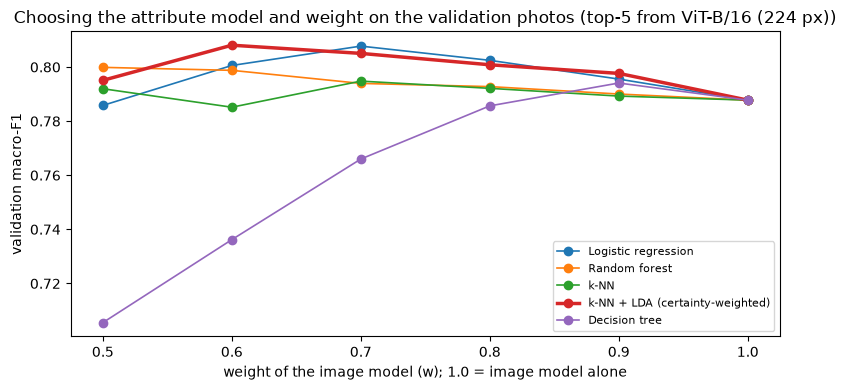

,attribute model,w (image),val accuracy,val macro-F1
0,k-NN + LDA (certainty-weighted),0.6,0.8107,0.8081
1,Logistic regression,0.7,0.8115,0.8077
2,Random forest,0.5,0.8032,0.7999
3,k-NN,0.7,0.7982,0.7948
4,Decision tree,0.9,0.7973,0.7941


In [5]:
rows = []
for name in ATTR_MODELS:
    for w in WEIGHTS:
        s = scores(y_val, consolidate(p_img_val, P_VAL[name], w))
        rows.append({"attribute model": name, "w (image)": w, "val accuracy": s["accuracy"], "val macro-F1": s["macro_f1"]})
weight_table = pd.DataFrame(rows)
best_per_model = (weight_table.sort_values(["val macro-F1", "w (image)"], ascending=[False, False])
                              .groupby("attribute model", sort=False).head(1).reset_index(drop=True))
BEST_MODEL, W = best_per_model.iloc[0]["attribute model"], float(best_per_model.iloc[0]["w (image)"])
print(f"chosen: {IMAGE_NAME} + {BEST_MODEL}, weight {W:.1f} image / {1 - W:.1f} attributes "
      f"(validation macro-F1 {best_per_model.iloc[0]['val macro-F1']:.4f})")

fig, ax = plt.subplots(figsize=(8, 4))
for name in ATTR_MODELS:
    t = weight_table[weight_table["attribute model"] == name]
    ax.plot(t["w (image)"], t["val macro-F1"], "o-", label=name, lw=2.5 if name == BEST_MODEL else 1.2)
ax.set_xlabel("weight of the image model (w); 1.0 = image model alone")
ax.set_ylabel("validation macro-F1")
ax.set_title(f"Choosing the attribute model and weight on the validation photos (top-{K} from {IMAGE_NAME})")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIGURES / "consolidation_weights.png", dpi=150, bbox_inches="tight")
plt.show()
best_per_model.round(4)

## 6. Final test (run once): Table 5

The chosen pair and weight are applied once to the test photos, next to each model on its own.

In [6]:
pred_img = p_img_test.argmax(1) + 1
pred_tab = P_TEST[BEST_MODEL].argmax(1) + 1
pred_con = consolidate(p_img_test, P_TEST[BEST_MODEL], W)

table5 = pd.DataFrame([
    {"model": f"Classical: {BEST_MODEL.lower()}", "data": "attributes", **scores(y_test, pred_tab)},
    {"model": f"Neural network: {IMAGE_NAME}", "data": "images", **scores(y_test, pred_img)},
    {"model": f"Consolidated (top-{K}, w = {W:.1f})", "data": "both", **scores(y_test, pred_con)}])
table5.round(4)

,model,data,accuracy,macro_f1
0,Classical: k-nn + lda (certainty-weighted),attributes,0.4436,0.4197
1,Neural network: ViT-B/16 (224 px),images,0.8202,0.8195
2,"Consolidated (top-5, w = 0.6)",both,0.8371,0.8358


### Every pair on the test set (for transparency)

Each attribute model with the weight it scored best with on validation. `fixed` = photos the consolidated model gets right and the image model alone gets wrong; `broken` = the reverse. The choice above was made on validation, not from this table.

In [7]:
img_ok = pred_img == y_test
rows = []
for _, r in best_per_model.iterrows():
    pred = consolidate(p_img_test, P_TEST[r["attribute model"]], r["w (image)"])
    ok = pred == y_test
    fixed, broken = int(np.sum(ok & ~img_ok)), int(np.sum(~ok & img_ok))
    rows.append({"attribute model": r["attribute model"], "w (image)": r["w (image)"],
                 "val macro-F1": r["val macro-F1"], **{f"test {k}": v for k, v in scores(y_test, pred).items()},
                 "fixed": fixed, "broken": broken})
all_pairs = pd.DataFrame(rows)
print(f"{IMAGE_NAME} alone: test accuracy {scores(y_test, pred_img)['accuracy']:.4f}, "
      f"macro-F1 {scores(y_test, pred_img)['macro_f1']:.4f}")
all_pairs.round(4)

ViT-B/16 (224 px) alone: test accuracy 0.8202, macro-F1 0.8195


,attribute model,w (image),val macro-F1,test accuracy,test macro_f1,fixed,broken
0,k-NN + LDA (certainty-weighted),0.6,0.8081,0.8371,0.8358,200,102
1,Logistic regression,0.7,0.8077,0.8400,0.8394,174,59
2,Random forest,0.5,0.7999,0.8343,0.8339,115,33
3,k-NN,0.7,0.7948,0.8278,0.8273,88,44
4,Decision tree,0.9,0.7941,0.8233,0.8226,45,27


## 7. Agreement between the two models: Table 6

For the chosen pair, each test photo falls into one outcome, based on the two models' own top predictions. The last column shows how often the consolidated prediction is right in each group: the interesting rows are "only the classical model is correct" (can the attributes rescue the image model?) and "only the neural network is correct" (does mixing in the attributes break good image predictions?).

In [8]:
tab_ok, con_ok = pred_tab == y_test, pred_con == y_test
outcome = np.select([img_ok & tab_ok, tab_ok & ~img_ok, img_ok & ~tab_ok, pred_img == pred_tab],
                    ["Both correct", "Only the classical model is correct", "Only the neural network is correct",
                     "Both wrong (same species)"], "Both wrong (different species)")
order = ["Both correct", "Only the classical model is correct", "Only the neural network is correct",
         "Both wrong (same species)", "Both wrong (different species)"]
table6 = (pd.DataFrame({"outcome": outcome, "consolidated correct": con_ok})
            .groupby("outcome").agg(photos=("consolidated correct", "size"),
                                    consolidated_correct=("consolidated correct", "sum"))
            .reindex(order).fillna(0).astype(int))
table6["share (%)"] = (100 * table6.photos / len(y_test)).round(1)
fixed, broken = int(np.sum(con_ok & ~img_ok)), int(np.sum(~con_ok & img_ok))
print(f"{BEST_MODEL} and {IMAGE_NAME} agree on {np.mean(pred_img == pred_tab):.1%} of test photos")
print(f"consolidation fixed {fixed} image-model mistakes and broke {broken} correct image predictions "
      f"(net {fixed - broken:+d})")
table6[["photos", "share (%)", "consolidated_correct"]]

k-NN + LDA (certainty-weighted) and ViT-B/16 (224 px) agree on 42.2% of test photos
consolidation fixed 200 image-model mistakes and broke 102 correct image predictions (net +98)


,photos,share (%),consolidated_correct
outcome,,,
Both correct,2326,40.1,2326
Only the classical model is correct,244,4.2,149
Only the neural network is correct,2426,41.9,2324
Both wrong (same species),120,2.1,0
Both wrong (different species),678,11.7,51


### Which species did the attributes help?

Photos the image model got wrong and the consolidated prediction got right, grouped by the image model's mistake.

In [9]:
species = feat_A.drop_duplicates("class_id").set_index("class_id")["class_name"].str.split(".", n=1).str[1].str.replace("_", " ")
changed = pd.DataFrame({"true species": species.loc[y_test].values, "image model said": species.loc[pred_img].values,
                        "fixed": con_ok & ~img_ok})
(changed[changed.fixed].groupby(["true species", "image model said"]).size()
        .sort_values(ascending=False).rename("photos fixed").head(10).reset_index())

,true species,image model said,photos fixed
0,Forsters Tern,Common Tern,4
1,Artic Tern,Common Tern,3
2,Baltimore Oriole,Hooded Oriole,3
3,American Crow,Fish Crow,3
4,Caspian Tern,Elegant Tern,3
5,Acadian Flycatcher,Least Flycatcher,2
6,Belted Kingfisher,Ringed Kingfisher,2
7,Bewick Wren,Black throated Sparrow,2
8,Acadian Flycatcher,Yellow bellied Flycatcher,2
9,American Crow,Brewer Blackbird,2


## 8. The same rule with the 448 px ViT

The 448 px ViT is the team's best image model (84.2% on its own). Only its **test** probabilities were saved, not validation ones, so its weight cannot be tuned without looking at the test set. Instead, the pair and weight chosen in section 5 (with the 224 px ViT, on validation) are reused **unchanged**. Nothing here is chosen from the test results, so there is still no test leakage; the weights may simply not be the best possible ones for the 448 px model. The final, validation-tuned 448 px ensemble is in vit_448px_consolidation.ipynb

Each attribute model is shown with the weight it was given in section 5. The pair chosen in section 5 is the headline result; the other rows are for reference.

In [10]:
TEST_448 = IMAGE_RUN / "vit_b16_448px_final_test_probs.npz"
vit448 = None
if TEST_448.exists():
    z = np.load(TEST_448)
    order = pd.Index(z["image_id"]).get_indexer(test_ids)             # same photos, put in the same order
    assert (order >= 0).all() and len(order) == len(test_ids)
    p448 = z["probs"][order]
    y448 = (z["class_id"] if "class_id" in z.files else z["labels"] + 1)[order]
    assert (y448 == y_test).all()
    ok448 = p448.argmax(1) + 1 == y_test
    rows = [{"model": "ViT-B/16 (448 px) alone", **scores(y_test, p448.argmax(1) + 1), "fixed": 0, "broken": 0}]
    for _, r in best_per_model.iterrows():
        pred = consolidate(p448, P_TEST[r["attribute model"]], r["w (image)"])
        ok = pred == y_test
        chosen = " (chosen in section 5)" if r["attribute model"] == BEST_MODEL else ""
        rows.append({"model": f"448 px ViT + {r['attribute model']}, w = {r['w (image)']:.1f}{chosen}",
                     **scores(y_test, pred), "fixed": int(np.sum(ok & ~ok448)), "broken": int(np.sum(~ok & ok448))})
    vit448 = pd.DataFrame(rows)
    print(f"ceiling (true species in the 448 px ViT's top {K}): {in_top_k(p448, y_test):.3f}")
    display(vit448.round(4))
else:
    print(f"{TEST_448.relative_to(ROOT)} not found: skipped")

ceiling (true species in the 448 px ViT's top 5): 0.957


,model,accuracy,macro_f1,fixed,broken
0,ViT-B/16 (448 px) alone,0.8416,0.8406,0,0
1,"448 px ViT + k-NN + LDA (certainty-weighted), ...",0.8540,0.8532,155,83
2,"448 px ViT + Logistic regression, w = 0.7",0.8550,0.8544,126,48
3,"448 px ViT + Random forest, w = 0.5",0.8524,0.8512,93,30
4,"448 px ViT + k-NN, w = 0.7",0.8476,0.8469,76,41
5,"448 px ViT + Decision tree, w = 0.9",0.8445,0.8438,38,21


## 9. Files written

All in `results/consolidation/`:
- `consolidation_results.json`: settings, the chosen pair and weight, Table 5, every pair on the test set, Table 6, and the 448 px ViT results from section 8
- `consolidation_weights.csv`: validation scores for every attribute model and weight
- `figures/consolidation_weights.png`: the chart from section 5

In [11]:
weight_table.to_csv(OUT / "consolidation_weights.csv", index=False)
results = {"image_model": {"name": IMAGE_NAME, "validation": str(img_val["model"]), "test": str(img_test["model"])},
           "attribute_models": list(ATTR_MODELS), "k_candidates": K, "weights_tried": WEIGHTS,
           "chosen": {"attribute_model": BEST_MODEL, "weight_image": W},
           "validation_photos": int(len(y_val)), "test_photos": int(len(y_test)),
           "single_models": single.to_dict("records"),
           "table5": table5.to_dict("records"),
           "all_pairs_test": all_pairs.to_dict("records"),
           "table6": table6.reset_index().to_dict("records"),
           "agreement": float(np.mean(pred_img == pred_tab)),
           "fixed": fixed, "broken": broken,
           "vit448_test": None if vit448 is None else vit448.to_dict("records")}
(OUT / "consolidation_results.json").write_text(json.dumps(results, indent=2))
sorted(str(p.relative_to(ROOT)) for p in OUT.rglob("*") if p.is_file())

['results\\consolidation\\consolidation_results.json',
 'results\\consolidation\\consolidation_weights.csv',
 'results\\consolidation\\figures\\consolidation_weights.png']